In [2]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import torch
import yaml

from u2_functions import calc_observables, show_results, topological_charge, topological_susceptibility, calc_wilson_loop_results
from u2_diffusion_model import u2_dm

device = 'cuda'
torch.set_default_device(device)

This serves primarily as an illustrative example on how to analyse the results. For proper generation of configurations, use the respective .py files `u2_generate_maala.py` and `u2_generate_reverse_sde.py`.

## Load trained network

In [4]:
network_path = "data/example_network/network.pt"
network_config_path = "data/example_network/training_config.yaml"
network = torch.load(network_path, map_location=device, weights_only=False)
with open(network_config_path, "r") as file:
    network_config = yaml.safe_load(file)

In [6]:
L = 16

my_dm = u2_dm(network, 
            grid_size=L, 
            sde_type=network_config["dm"]["sde_type"], 
            sde_param=network_config["dm"]["sde_param"], 
            t_max=network_config["dm"]["t_max"], 
            t_n=network_config["dm"]["t_n"],
            use_log_spaced_t=True,
            t_log_min=network_config["dm"]["t_log_min"],
            t_log_max=network_config["dm"]["t_log_max"])

# Run generative process - MAALA

In [8]:
(samples, 
 history, 
 metropolis_acc_rate_hist) = my_dm.maala_sampler(n=100, 
                                                beta=2., 
                                                beta_0=2., 
                                                dtau=5e-3, 
                                                n_tau=25, 
                                                metropolis_threshold=0.95, 
                                                analytic_action_step=False, 
                                                return_hist=True,
                                                return_topo_charge_hist=False,
                                                save_intermediate_configs=False, 
                                                progress_bar=True,
                                                n_resample=100)

100%|██████████| 799/799 [01:42<00:00,  7.81it/s]


In [9]:
show_results(samples)

Average plaquette: +0.248(2)
Topological susceptibility: +0.06(1)


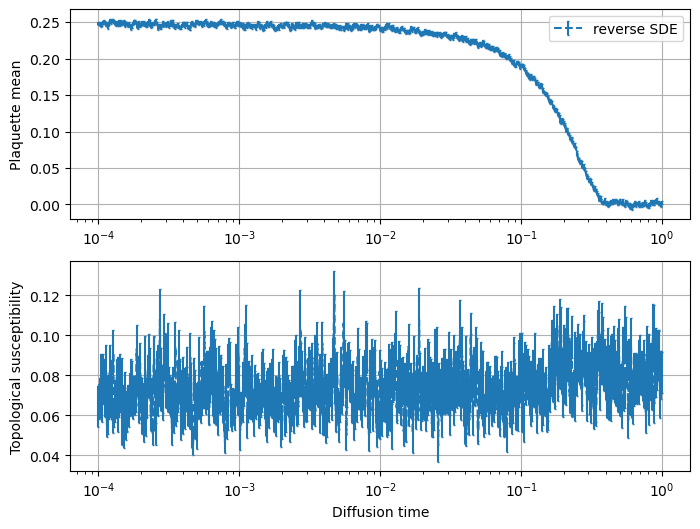

In [10]:
fig, ax = plt.subplots(2,1, figsize=(8,6))

ax[0].errorbar(history['t'], history['avg_plaquette'][:,0], yerr=history['avg_plaquette'][:,1], 
               fmt='--', capsize=1, label=r'reverse SDE')
ax[0].grid()
ax[0].set_ylabel('Plaquette mean')
ax[0].legend()
ax[0].semilogx()

ax[1].errorbar(history['t'], history['topo_susc'][:,0], yerr=history['topo_susc'][:,1], 
               fmt='--', capsize=1, label=r'reverse SDE')
ax[1].grid()
ax[1].set_xlabel('Diffusion time')
ax[1].set_ylabel('Topological susceptibility')
ax[1].semilogx()

plt.show()

# Run generative process - reverse SDE

In [11]:
samples, history = my_dm.solve_reverse_sde(n=100,
                                           n_steps=1000, 
                                           return_hist=True, 
                                           n_resample=100, 
                                           progress_bar=True)

100%|██████████| 999/999 [00:31<00:00, 32.21it/s]


In [12]:
show_results(samples)

Average plaquette: +0.249(2)
Topological susceptibility: +0.073(9)


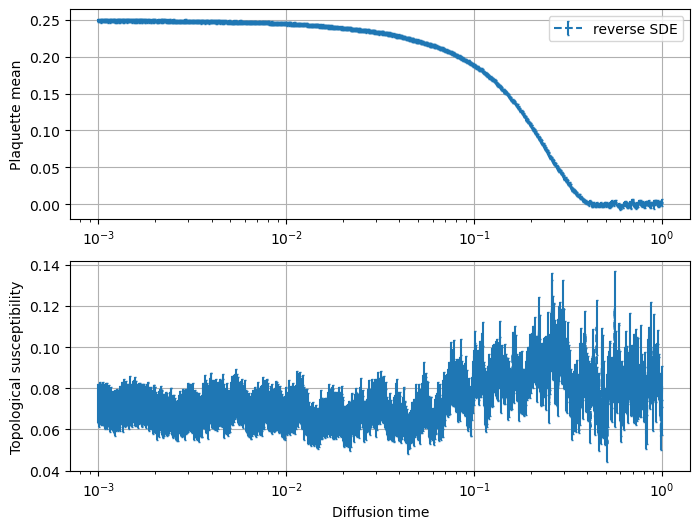

In [13]:
fig, ax = plt.subplots(2,1, figsize=(8,6))

ax[0].errorbar(history['t'], history['avg_plaquette'][:,0], yerr=history['avg_plaquette'][:,1], 
               fmt='--', capsize=1, label=r'reverse SDE')
ax[0].grid()
ax[0].set_ylabel('Plaquette mean')
ax[0].legend()
ax[0].semilogx()

ax[1].errorbar(history['t'], history['topo_susc'][:,0], yerr=history['topo_susc'][:,1], 
               fmt='--', capsize=1, label=r'reverse SDE')
ax[1].grid()
ax[1].set_xlabel('Diffusion time')
ax[1].set_ylabel('Topological susceptibility')
ax[1].semilogx()

plt.show()